# 03 · Statistical associations and model assumptions

This notebook separates exploratory **statistical association** from **predictive modeling**. Because the dataset is small and not randomly sampled, conventional asymptotic approximations are often unreliable. Results cannot establish causal effects of charging policies or costs.

## Reproducible environment

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'ev_research').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.ev_research.data import load_survey, sample_audit, cleaning_audit
from src.ev_research.config import FIGURES, TABLES, FEATURE_SETS, SOURCE_INDEX
from src.ev_research.plotting_style import apply_style
from src.ev_research.statistics import prevalence_table, assumptions_audit, fisher_associations, sensitivity_table
from src.ev_research.figures import *
apply_style()
raw, unique, eligible = load_survey()
print(f'Raw: {len(raw)} | Distinct: {len(unique)} | Eligible: {len(eligible)}')
def show_figure(path, width=1150):
    """Display the exact saved PNG (also exported as vector SVG)."""
    assert path.exists(), f'Missing figure: {path}'
    display(Image(filename=str(path), width=width))


Raw: 105 | Distinct: 92 | Eligible: 62


## 1. Assumption audit for binary classification

**Logistic regression:** binary response, conditionally independent respondent units, correct log-odds functional form for modeled numeric relationships, absence of complete separation, and sufficient events per effective coefficient. Multicollinearity can destabilize estimated coefficients. Normality of original predictors is **not** required.

**Linear SVM:** binary labels and suitable scaling/encoding; selected hyperparameters are learned entirely within each training fold. Scores are margins, not calibrated probabilities.

**Random Forest / LightGBM:** no Gaussian feature assumption, but deep trees can overfit tiny categorical samples and rare categories. Importance is descriptive predictive relevance, not evidence of intervention effects.

**Design limitation:** the survey does not establish independent random sampling from a national population. Repeated companies cannot be checked from anonymous raw records.

In [2]:
assumptions = assumptions_audit(eligible)
display(assumptions.groupby(['outcome','scenario']).agg(
    checked_categories=('category','count'),
    rare_categories=('rare_under_3','sum'),
    single_class_categories=('single_class','sum')).reset_index())
display(assumptions.query('rare_under_3').head(20))

,outcome,scenario,checked_categories,rare_categories,single_class_categories
0,ev_consideration,fleet_baseline,13,1,3
1,ev_consideration,operational_extended,32,3,7
2,ev_use,fleet_baseline,13,1,1
3,ev_use,operational_extended,32,3,4


,outcome,scenario,feature,category,n,negative,positive,rare_under_3,single_class
8,ev_use,fleet_baseline,fleet_size,Missing,1,0,1,True,True
21,ev_use,operational_extended,fleet_size,Missing,1,0,1,True,True
37,ev_use,operational_extended,route_planning,Missing,1,0,1,True,True
42,ev_use,operational_extended,sector,Missing,1,0,1,True,True
53,ev_consideration,fleet_baseline,fleet_size,Missing,1,0,1,True,True
66,ev_consideration,operational_extended,fleet_size,Missing,1,0,1,True,True
82,ev_consideration,operational_extended,route_planning,Missing,1,0,1,True,True
87,ev_consideration,operational_extended,sector,Missing,1,0,1,True,True


## 2. Fisher exact tests and multiple comparisons

For a 2×2 table, the sample odds ratio is

$$\widehat{OR}=\frac{n_{11} n_{00}}{n_{10} n_{01}},$$

with attention to zero cells and wide uncertainty. Fisher’s exact test conditions on table margins. Multiplicity across related exposures is controlled descriptively using Benjamini–Hochberg FDR. Approximate OR intervals are **not** exact Fisher intervals.

,outcome,exposure,n,exposed_positives,exposed_n,unexposed_positives,unexposed_n,odds_ratio,or_95_low_approx,or_95_high_approx,fisher_p,fdr_bh_q
0,ev_consideration,barrier_range,58,9,23,24,35,0.294643,0.098056,0.885358,0.033438,0.267507
1,ev_consideration,logistics_sector,58,18,37,15,21,0.378947,0.120542,1.191294,0.107243,0.383277
2,ev_consideration,barrier_acquisition_cost,58,11,24,22,34,0.461538,0.158716,1.342136,0.185070,0.383277
3,ev_consideration,fleet_over_ten,58,18,27,15,31,2.133333,0.734658,6.194868,0.191639,0.383277
4,ev_consideration,large_firm,59,14,20,20,39,2.216667,0.706055,6.959245,0.265615,0.424984
5,ev_consideration,distance_over_sixty_km,52,12,25,16,27,0.634615,0.211733,1.902100,0.578294,0.771059
6,ev_consideration,barrier_charging_infrastructure,58,12,20,21,38,1.214286,0.404348,3.646587,0.785958,0.898237
7,ev_consideration,preplanned_routes,58,9,15,24,43,1.187500,0.359267,3.925092,1.000000,1.000000
8,ev_use,fleet_over_ten,59,11,28,3,31,6.039216,1.471942,24.778235,0.012878,0.076993
9,ev_use,barrier_acquisition_cost,58,2,24,12,34,0.166667,0.033336,0.833277,0.027852,0.076993


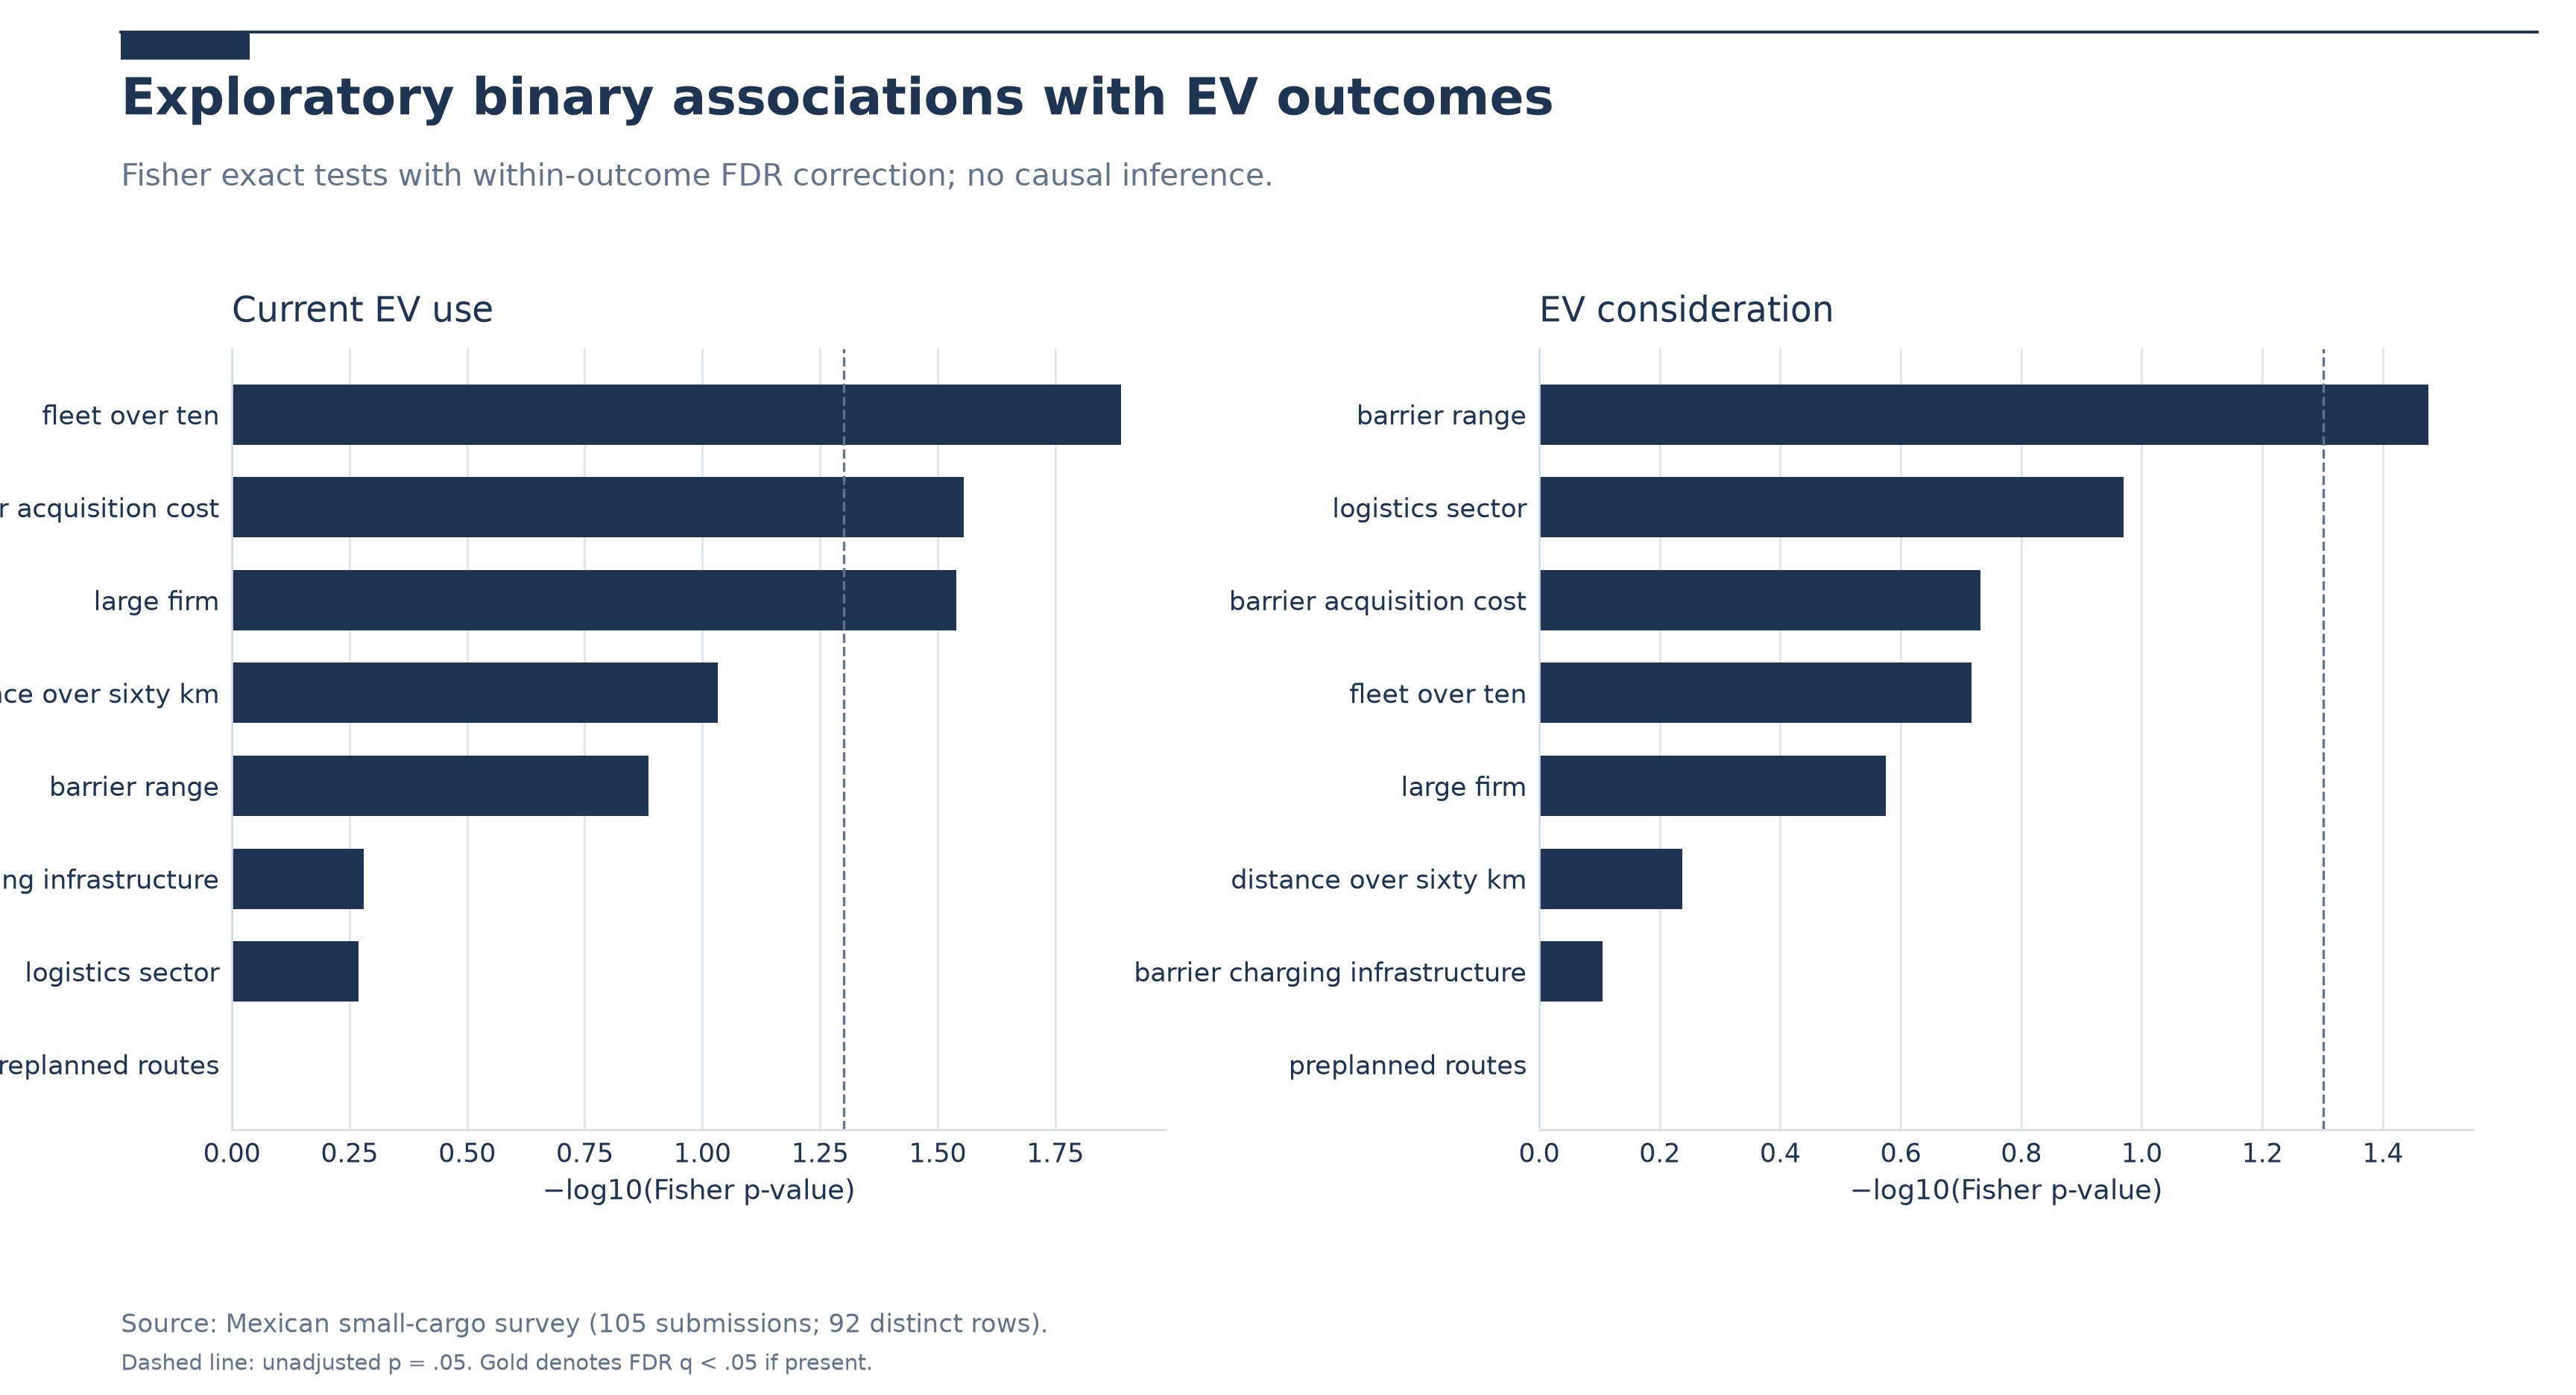

In [3]:
associations=fisher_associations(eligible)
display(associations)
plot_association_overview(associations)
show_figure(FIGURES/'05_statistical_associations'/'01_fisher_associations.png')

## 3. Interpretation boundaries

Association tests here are exploratory. Non-significant p-values do not imply absence of an effect. Significant p-values (if any) do not imply causality. No firm-level policy exposure variable was independently measured, and no instrumental-variable or experimental identification strategy was available.